# Looking inside a network

Networks as data, without building them: the documentation tool
(`kromex_doc`, also the `kromex-doc` command) evaluates the rates from
the network file, finds the jumps of piecewise rates and the missing
chemistry, and shows the photo cross sections; the converters
(`kromex_convert`) turn KIDA and UMIST networks into `.knet` files.

In [1]:
%matplotlib inline
import matplotlib
matplotlib.rcParams['figure.dpi'] = 90

In [2]:
# KROME-X: installed with pip, or this checkout (two folders up)
import sys, pathlib
try:
    import kromex
except ImportError:
    sys.path.insert(0, str(pathlib.Path.cwd().resolve().parents[1]))
    import kromex

## A network's documentation

`document()` writes the HTML site and the LaTeX table (the command line,
in a terminal, also serves it on http://127.0.0.1:8080/). The site is in
`build_doc_primordial/index.html`.

In [3]:
import kromex, knet, paths     # the parser and the data paths of KROME-X
from kromex_doc import document, evaluate, latex, missing, chem, photo

index = document("primordial", "build_doc_primordial", quiet=True)
print(index)

build_doc_primordial/index.html


The pieces behind it are available too. The rate coefficients of
H + H+ -> H2+, a rate written in two temperature ranges, evaluated from
the network's expressions:

at 6700 K the pieces give 1.43e-16 and 1.57e-16: a jump of 10.2%


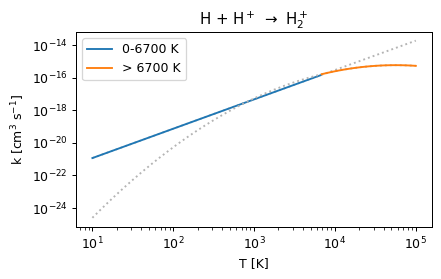

In [4]:
import numpy as np
import matplotlib.pyplot as plt

net = knet.parse_network(paths.find("primordial", "networks", suffix=".knet"))
pieces = [rx for rx in net.reactions if rx["eq"] == "H + H+ -> H2+"]
T = np.logspace(1, 5, 300)
fig, a = plt.subplots(figsize=(5, 3.2))
for rx in pieces:
    k = evaluate.Evaluator(net, {"Tgas": T}).rate(rx)
    lo, hi = rx["trange"]
    m = (T >= lo) & (T < hi)
    a.loglog(T, k, ":", color="0.7")
    a.loglog(T[m], k[m], label=("> %g K" % lo) if np.isinf(hi) else "%g-%g K" % (lo, hi))
a.set(xlabel="T [K]", ylabel=r"k [cm$^3$ s$^{-1}$]", title="H + H$^+$ $\\to$ H$_2^+$")
a.legend(); fig.tight_layout()
for Tb, kl, kr, err in evaluate.joints(net, pieces, {}):
    print("at %g K the pieces give %.3g and %.3g: a jump of %.1f%%" % (Tb, kl, kr, 100 * err))

The formula as it goes into the reaction table of a paper:

In [5]:
tex = latex.Tex(net)
for rx in pieces:
    print(latex.reaction_math(rx), latex.rate_tex(rx, tex), latex.trange_tex(rx["trange"]))

$\mathrm{H} + \mathrm{H}^{+} \rightarrow \mathrm{H}_{2}^{+}$ $1.85\times10^{-23}\,{T}^{1.8}$ $T < 6700$\,K
$\mathrm{H} + \mathrm{H}^{+} \rightarrow \mathrm{H}_{2}^{+}$ $5.81\times10^{-16}\,{\left(\frac{T}{56200}\right)}^{-0.6657\,\log_{10}\left(\frac{T}{56200}\right)}$ $6700 \leq T$\,K


## Missing chemistry

Reactant sets the network never uses, with candidate products of the
same elements and charge, ranked by the reaction enthalpy at 298 K
(Burcat's database; negative is exothermic):

In [6]:
m = missing.analyse(net, chem.Thermo())["phases"]["gas"]
for x in m["missing"][:8]:
    best = x["products"][0]
    dH = "%.0f K" % best["dH"] if best["dH"] is not None else "no data"
    print("%-12s -> %-14s dH = %s" % (" + ".join(x["reactants"]), " + ".join(best["species"]), dH))

H-           -> H + e-         dH = 9497 K
H2           -> H + H          dH = 52438 K
HD           -> D + H          dH = 51863 K
D + H        -> HD             dH = -51863 K
D + H2+      -> D+ + H2        dH = -21177 K
D + He+      -> D+ + He        dH = -127478 K
D+ + H-      -> HD             dH = -200956 K
D+ + He      -> D + He+        dH = 127478 K


## Photo cross sections

The CO photodissociation cross section from the two databases KROME-X
reads, and the unshielded rate in the Draine (1978) field: the SWRI
table misses most of CO's predissociating lines.

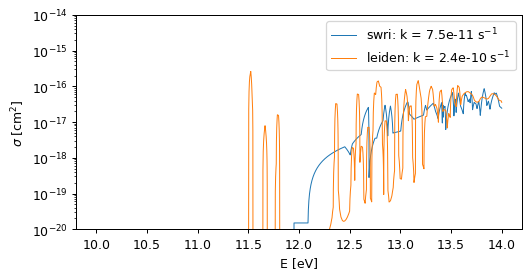

In [7]:
import pathlib
d = pathlib.Path("build_networks")      # the files of this notebook
d.mkdir(exist_ok=True)
fig, a = plt.subplots(figsize=(6, 3.2))
for src in ("swri", "leiden"):
    f = d / ("co_%s.knet" % src)
    f.write_text('krome_format 1\nCO -> C + O  []  photo(xsec="%s")\n' % src)
    x = list(photo.xsecs(knet.parse_network(f))[0].values())[0]
    E = x.grid(10.0, 14.0, 4000)
    a.semilogy(E, x(E), lw=0.8, label="%s: k = %.2g s$^{-1}$" % (src, x.draine_rate()))
a.set(xlabel="E [eV]", ylabel=r"$\sigma$ [cm$^2$]", ylim=(1e-20, 1e-14))
a.legend(); fig.tight_layout()

## Networks from KIDA and UMIST

The converters read the databases' own files (here a few lines of
kida.uva.2024 and of RATE22) and write `.knet` networks, with the
databases' rate formulae.

In [8]:
from kromex_convert import kida2krome, umist2krome

kida_lines = """\
N2         CR                     N          N                                             5.000e+00  0.000e+00  0.000e+00 1.25e+00 0.00e+00 logn  1  -9999   9999  1     1 1  1
HNSi       C+                     H          SiNC+                                         1.000e+00  1.810e-09  3.770e-01 2.00e+00 0.00e+00 logn  4     10     10  4   657 1  1
HNSi       C+                     H          SiNC+                                         1.000e+00  1.810e-09  3.770e-01 2.00e+00 0.00e+00 logn  4     11    800  5   657 2  1
"""
src = d / "kida.in"; src.write_text(kida_lines)
kida2krome.convert(src).write(d / "kida.knet", ["a KIDA excerpt"])
print((d / "kida.knet").read_text())

wrote build_networks/kida.knet: 3 reactions, 6 species
krome_format 1
# converted from kida.in (KIDA kida.uva format) by kromex_convert
# a KIDA excerpt

param crflux       = 1.3e-17    # cosmic-ray ionisation rate of H2 zeta [s^-1] (KIDA: k = alpha zeta)
param uv_scale     = 1          # the UV field in units of Draine's (1978) (KIDA photorates)

# KIDA 1 (itype 1, formula 1)
N2 -> N + N                              []                 5*crflux
# KIDA 657 (itype 4, formula 4; gap 10-11 K closed: the piece below extends to 11)
HNSi + C+ -> H + SiNC+                   [10, 11]           1*1.81e-09*(0.62 + 0.4767*0.377*sqrt(300/Tgas))
# KIDA 657 (itype 4, formula 5)
HNSi + C+ -> H + SiNC+                   [11, 800]          1*1.81e-09*(1 + 0.0967*0.377*sqrt(300/Tgas) + 0.377**2/10.526*300/Tgas)



In [9]:
umist_lines = """\
74:AD:H-:H:H2:e-:::2:4.82e-09:0.02:4.3:10:100:M:A:"10.1103/PhysRevA.82.042708":"06_4031D.notes":4.32e-09:-0.39:39.4:101:3000:M:A:"10.1103/PhysRevA.82.042708":"06_4031D.notes":
833:CR:C-:CRPHOT:C:e-:::1:1.30e-17:0.00:250.0:10:41000:E:C:"10.1051/0004-6361/201220465":"06_CRPHOT.notes":
8057:PH:C-:PHOTON:C:e-:::1:1.45e-08:0.00:0.5:10:41000:C:C:"":"NIST EA - Millar":
"""
src = d / "rate22.rates"; src.write_text(umist_lines)
umist2krome.convert(src).write(d / "umist.knet", ["a RATE22 excerpt"])
print((d / "umist.knet").read_text())

wrote build_networks/umist.knet: 4 reactions, 6 species
krome_format 1
# converted from rate22.rates (UMIST RATE format) by kromex_convert
# a RATE22 excerpt

param crflux       = 1.36e-17   # cosmic-ray ionisation rate zeta [s^-1]; the CP and CR rates scale as zeta / 1.36e-17
param uv_scale     = 1          # the UV field in units of the database's unshielded interstellar field (PH rates)

# UMIST 74 AD (gap 100-101 K closed: the piece below extends to 101)
ref doi:10.1103/PhysRevA.82.042708
H- + H -> H2 + e-                        [10, 101]          4.82e-09*(Tgas/300)**(0.02)*exp(-(4.3)/Tgas)
# UMIST 74 AD (range 2 of 2)
ref doi:10.1103/PhysRevA.82.042708
H- + H -> H2 + e-                        [101, 3000]        4.32e-09*(Tgas/300)**(-0.39)*exp(-(39.4)/Tgas)
# UMIST 833 CR
ref doi:10.1051/0004-6361/201220465
C- -> C + e-                             []                 1.3e-17*250/(1-0.5)*crflux/1.36e-17
# UMIST 8057 PH
C- -> C + e-                             []                 1.4